# Program 09: BadTeacher, a real unlearning baseline

**What:** implement BadTeacher-style unlearning (Chundawat et al., "Can Bad Teaching Induce Forgetting?", AAAI 2023).

**How:** use two teachers: the trained model ("good") and a randomly initialized model ("bad"). The student starts as a copy of the trained model. On retain data, minimize KL to the good teacher. On forget data, minimize KL to the bad teacher.

**Why:** UnCLe uses BadTeacher as a main baseline, and UniCLUN is built on it. You will reuse this code in Phase D.

**Understanding note:** "forgetting" can be defined as "answer like a random network would", which is gentler than gradient ascent and keeps the model stable.

**Done when:** FA drops near chance level (about 10% for 10 classes), with RA close to the original.

## Where this fits (for a first-time reader)

| Program | What it did | Problem |
|---|---|---|
| 07 retrain | trained without cats from scratch: the ideal | too slow to repeat for every deletion |
| 08 gradient ascent | maximize the loss on cats | the loss has no limit: it destroyed the model (NaN at step 13) |
| 08 random labels | teach cats random wrong labels, plus normal retain batches | worked on the numbers, but left a fingerprint: very low confidence on cats (29% vs the ideal's 84%) |
| **09 BadTeacher** | copy a **random network's** answers on cats, and the **original model's** answers on everything else | ? |

BadTeacher fixes gradient ascent's problem: its target on cats is something you can actually reach (a random network's outputs), so the loss bottoms out at 0 instead of growing forever. And on retain data it copies the original model's full outputs, not just labels, which preserves much more (the same "dark knowledge" idea as DER++ in program 06).

Terms: **FA** = accuracy on cat test images, **RA** = accuracy on the other 9 classes, **KL** = KL divergence, a measure of how different two probability distributions are (0 = identical).

## 1. Setup

Settings follow the BadTeacher paper's public code: Adam with lr 1e-4, **one** epoch, a random 30% of the retain data, temperature 1.

Memory: `workers` is 0 (images loaded in the main process). One epoch is only about 70 steps, so that is fast enough, and it saves about 2 GB of RAM.

In [1]:
import copy, gc, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train
for module in (common.utils, common.data, common.models, common.train):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

from common.data import get_cifar10_unlearning_loaders
from common.models import resnet18_cifar
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "forget_class": 3,        # cat
    "seed": 0,
    "workers": 0,             # 0 = load images in the main process (saves ~2 GB of RAM)
    "retain_fraction": 0.3,   # share of the retain set used (the paper uses 30%)
    "forget_batch": 64,       # cat images per step
    "retain_batch": 192,      # retain images per step (keeps roughly the paper's forget:retain mix)
    "lr": 1e-4,               # Adam, as in the paper
    "epochs": 1,              # one pass over the retain subset, as in the paper
    "temperature": 1.0,       # softens both distributions before comparing; 1 = no change
    "bad_teacher_seed": 0,    # first seed tried for the random network (see section 3)
}
device = get_device()
print("device:", device)

device: cuda


## 2. Data, measuring tools, and the starting point

Same as program 08:
- All 10,000 test images are loaded **once** into GPU memory, so every check is fast and needs no loader processes.
- After each step we check FA on all 1,000 cat test images and RA on a fixed sample of 2,000 other test images.
- `full_eval` measures one model on all 10,000 and returns **numbers only**.

We also load program 07's reference (the ideal) and program 08's final numbers from the run log, so section 7 can compare all methods side by side.

In [2]:
loaders = get_cifar10_unlearning_loaders(SETTINGS["forget_class"], batch_size=128, num_workers=SETTINGS["workers"])
classes = loaders["classes"]
FORGET = SETTINGS["forget_class"]

# All test images, loaded once into GPU memory.
test_set = loaders["test_all"].dataset
xs, ys = zip(*(test_set[i] for i in range(len(test_set))))
X_test, Y_test = torch.stack(xs).to(device), torch.tensor(ys, device=device)
del xs, ys
gc.collect()
cat_mask = Y_test == FORGET

rng = np.random.RandomState(SETTINGS["seed"])
retain_idx = torch.where(~cat_mask)[0].cpu().numpy()
pick = torch.from_numpy(rng.choice(retain_idx, 2000, replace=False)).to(device)
X_fa = X_test[cat_mask]
X_ra, Y_ra = X_test[pick], Y_test[pick]


@torch.no_grad()
def logits_of(model, X, chunk=1000):
    model.eval()
    return torch.cat([model(X[i:i + chunk]) for i in range(0, len(X), chunk)])


def quick_eval(model):
    """(FA, RA) on the per-step check sets."""
    fa = (logits_of(model, X_fa).argmax(1) == FORGET).float().mean().item()
    ra = (logits_of(model, X_ra).argmax(1) == Y_ra).float().mean().item()
    return fa, ra


def full_eval(model):
    """Numbers only, on all 10,000 test images: FA, RA, confidence on cats, where cat images go."""
    out = logits_of(model, X_test).float()
    pred = out.argmax(1)
    acc = np.array([(pred[Y_test == c] == c).float().mean().item() for c in range(10)])
    probs_cat = torch.softmax(out[cat_mask], dim=1)
    share = torch.bincount(probs_cat.argmax(1), minlength=10).float() / len(probs_cat)
    return {"fa": float(acc[FORGET]), "ra": float(np.delete(acc, FORGET).mean()),
            "cat_conf": probs_cat.max(1).values.mean().item(), "pred_share": share.cpu().numpy()}


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


results = {}   # model name -> numbers from full_eval

original_path = RESULTS_DIR / "01_resnet18_cifar10.pt"
if not original_path.exists():
    raise FileNotFoundError(f"{original_path} not found. Run program 01 first.")
original = resnet18_cifar(num_classes=10).to(device)
original.load_state_dict(torch.load(original_path, map_location=device))
original.eval()
fa0, ra0 = quick_eval(original)
results["original (01)"] = full_eval(original)
print(f"original model: FA {results['original (01)']['fa']*100:.1f}%  RA {results['original (01)']['ra']*100:.1f}%")

ref_path = RESULTS_DIR / "07_retrain_reference.npz"
retrain_ref = np.load(ref_path) if ref_path.exists() else None
if retrain_ref is not None:
    ra_retrain = float(np.delete(retrain_ref["per_class_acc"], FORGET).mean())
    print(f"retrain model (07):  FA {retrain_ref['per_class_acc'][FORGET]*100:.1f}%  RA {ra_retrain*100:.1f}%")

# Program 08's final numbers, from the run log (if program 08 was run).
prog08 = None
log_path = RESULTS_DIR / "runs.jsonl"
if log_path.exists():
    for line in log_path.read_text().splitlines():
        entry = json.loads(line)
        if entry["program"] == "08_simple_unlearn":
            prog08 = entry["results"]["full_test"]      # keep the latest run
print("program 08 results found" if prog08 else "program 08 results not found: section 7 will skip them")

original model: FA 85.7%  RA 94.5%
retrain model (07):  FA 0.0%  RA 94.9%
program 08 results found


## 3. The two teachers and the student

- **Good teacher** = the original model (program 01). Frozen. It knows everything, cats included.
- **Bad teacher** = a ResNet-18 with **random weights**, never trained. Frozen. It knows nothing.
- **Student** = a copy of the original model. This is the only model that gets updated, and it becomes the unlearned model.

So three models are on the GPU during unlearning: about 135 MB, well within the 4 GB GPU.

**What does a random network answer?** Not a neat "10% for every class". In a test of five random seeds, every random ResNet-18 gave **almost every image the same answer**, at about 25–35% probability, with the other classes sharing the rest:

| seed | favourite class (all images) | probability of "cat" on cat images |
|---|---|---|
| 0 | **cat** | 34% |
| 1 | truck | 15% |
| 2 | frog | 1% |
| 3 | frog | 10% |
| 4 | **cat** | 30% |

With seed 0 or 4 the "bad" teacher's favourite answer is the very class we want to forget. A student that copies it would keep answering "cat" for cats, and forgetting would fail.

So the cell below **checks the random network before using it**: if its most common answer on cat images is "cat", that network is rejected and the next seed is tried. The paper doesn't mention this, but it matters: what BadTeacher's "forgotten" state looks like depends on which random network you happened to draw.

The cell then shows what the chosen bad teacher says about cat images: which class it picks, how confident it is, and how spread out its answers are (entropy: 2.30 means perfectly uniform over 10 classes, 0 means always certain).

In [3]:
good_teacher = original                         # already loaded and frozen

# Draw a random network; reject it if its favourite answer on cat images is "cat".
bad_seed = SETTINGS["bad_teacher_seed"]
while True:
    set_seed(bad_seed)
    bad_teacher = resnet18_cifar(num_classes=10).to(device).eval()   # random weights, never trained
    favourite = int(logits_of(bad_teacher, X_fa).argmax(1).mode().values)
    if favourite != FORGET:
        break
    print(f"bad teacher seed {bad_seed}: favourite answer on cat images is '{classes[favourite]}' -> rejected")
    bad_seed += 1
print(f"bad teacher: seed {bad_seed} (favourite answer on cat images: '{classes[favourite]}')\n")
for p in list(good_teacher.parameters()) + list(bad_teacher.parameters()):
    p.requires_grad_(False)

student = copy.deepcopy(original)
for p in student.parameters():
    p.requires_grad_(True)

with torch.no_grad():
    bad_probs = torch.softmax(logits_of(bad_teacher, X_fa).float(), dim=1)
bad_share = (torch.bincount(bad_probs.argmax(1), minlength=10).float() / len(bad_probs)).cpu().numpy()
entropy = -(bad_probs * bad_probs.clamp_min(1e-12).log()).sum(1).mean().item()
print("bad teacher on cat test images:")
print(f"  average top-class probability: {bad_probs.max(1).values.mean().item()*100:.1f}%  (uniform would be 10%)")
print(f"  average entropy: {entropy:.2f}  (uniform = {np.log(10):.2f})")
print(f"  average probability of 'cat': {bad_probs[:, FORGET].mean().item()*100:.1f}%")
print("  picks: " + ", ".join(f"{classes[c]} {bad_share[c]*100:.0f}%" for c in np.argsort(-bad_share) if bad_share[c] > 0.01))

bad teacher seed 0: favourite answer on cat images is 'cat' -> rejected
bad teacher: seed 1 (favourite answer on cat images: 'truck')

bad teacher on cat test images:
  average top-class probability: 24.7%  (uniform would be 10%)
  average entropy: 2.11  (uniform = 2.30)
  average probability of 'cat': 14.6%
  picks: truck 99%


## 4. The BadTeacher loss

Each step takes a batch of **64 cat images** and **192 retain images**. Every image gets a teacher:
- cat image → the **bad** teacher's output distribution
- retain image → the **good** teacher's output distribution

The student is trained to match its teacher's distribution, using KL divergence:

$$\mathcal{L} = \text{KL}\big(\,p_{\text{teacher}}(x) \;\|\; p_{\text{student}}(x)\,\big), \qquad p = \text{softmax}(\text{logits} / T)$$

Why this is better than program 08's methods:

| | Program 08 | BadTeacher |
|---|---|---|
| Forget signal | GA: "make the cat loss as big as possible" (no limit) | "match a random network on cats": KL bottoms out at 0 once matched |
| Retain signal | RL: true labels only (or nothing, for GA) | the original model's **full output distribution**, which keeps its dark knowledge (like DER++'s stored logits) |
| When does it stop pushing? | never (GA) | when the student matches both teachers |

**Temperature T** divides the logits before softmax. T > 1 makes both distributions softer, so small differences between classes matter more. The paper uses T = 1 (no change).

We also record the forget part and the retain part of the loss separately, so you can see which one dominates.

In [4]:
def badteacher_loss(student_logits, good_logits, bad_logits, is_forget, T):
    """KL(teacher || student), where each image's teacher is bad (cat) or good (retain)."""
    teacher_logits = torch.where(is_forget[:, None], bad_logits, good_logits)
    log_p_student = F.log_softmax(student_logits / T, dim=1)
    p_teacher = F.softmax(teacher_logits / T, dim=1)
    per_image = F.kl_div(log_p_student, p_teacher, reduction="none").sum(1)   # one KL value per image
    return per_image.mean(), per_image[is_forget].mean().item(), per_image[~is_forget].mean().item()

## 5. Unlearn

The training data:
- **cat images**: all 5,000 training cats, cycled as needed;
- **retain images**: a fixed random 30% of the retain training set (13,500 images). One epoch = one pass over these, about 70 steps.

**BatchNorm stays frozen** (`student.eval()` while updating), as in program 08, so only the weights change and the result is comparable. FA and RA are checked after every step; one epoch takes well under a minute.

In [5]:
retain_ds = loaders["train_retain"].dataset
keep = rng.choice(len(retain_ds), int(len(retain_ds) * SETTINGS["retain_fraction"]), replace=False)
retain_loader = DataLoader(Subset(retain_ds, keep.tolist()), batch_size=SETTINGS["retain_batch"],
                           shuffle=True, drop_last=True, num_workers=SETTINGS["workers"])
forget_loader = DataLoader(loaders["train_forget"].dataset, batch_size=SETTINGS["forget_batch"],
                           shuffle=True, drop_last=True, num_workers=SETTINGS["workers"])

def forever(loader):
    while True:
        for batch in loader:
            yield batch

print(f"retain subset: {len(keep)} images, {len(retain_loader)} steps per epoch")

set_seed(SETTINGS["seed"])
optimizer = torch.optim.Adam(student.parameters(), lr=SETTINGS["lr"])
forget_iter = forever(forget_loader)
hist = {"step": [0], "fa": [fa0], "ra": [ra0], "kl_forget": [np.nan], "kl_retain": [np.nan]}
start = time.time()
step = 0
for epoch in range(SETTINGS["epochs"]):
    for xr, _ in retain_loader:
        xf, _ = next(forget_iter)
        x = torch.cat([xf, xr]).to(device)
        is_forget = torch.cat([torch.ones(len(xf)), torch.zeros(len(xr))]).bool().to(device)

        with torch.no_grad():
            good_logits = good_teacher(x)
            bad_logits = bad_teacher(x)
        student.eval()                                   # BatchNorm frozen
        loss, kl_f, kl_r = badteacher_loss(student(x), good_logits, bad_logits, is_forget, SETTINGS["temperature"])

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        step += 1
        fa, ra = quick_eval(student)
        for k, v in zip(hist, [step, fa, ra, kl_f, kl_r]):
            hist[k].append(v)
        if step % 10 == 0 or step == 1:
            print(f"step {step:3d}: FA {fa*100:5.1f}%  RA {ra*100:5.1f}%  "
                  f"KL forget {kl_f:.3f}  KL retain {kl_r:.4f}  ({time.time()-start:.0f}s)")
seconds = time.time() - start
print(f"\ndone: {step} steps in {seconds:.0f}s")

retain subset: 13500 images, 70 steps per epoch
step   1: FA   7.3%  RA  93.8%  KL forget 6.833  KL retain -0.0000  (2s)
step  10: FA   0.1%  RA  92.4%  KL forget 0.361  KL retain 0.2343  (15s)
step  20: FA   7.8%  RA  92.5%  KL forget 0.191  KL retain 0.0401  (30s)
step  30: FA   0.2%  RA  93.9%  KL forget 0.107  KL retain 0.0696  (44s)
step  40: FA   4.5%  RA  95.1%  KL forget 0.096  KL retain 0.0342  (59s)
step  50: FA   6.3%  RA  94.7%  KL forget 0.065  KL retain 0.0358  (73s)
step  60: FA   1.2%  RA  94.8%  KL forget 0.074  KL retain 0.0325  (88s)
step  70: FA   1.9%  RA  95.3%  KL forget 0.084  KL retain 0.0174  (103s)

done: 70 steps in 103s


## 6. The curves

Left: FA and RA after every step, with reference lines for the original RA, the retrain model's FA (0%) and chance level (10%). Right: the two parts of the loss.

Compare with program 08: does RA stay close to the original the whole time, or is there a dip like random labels had?

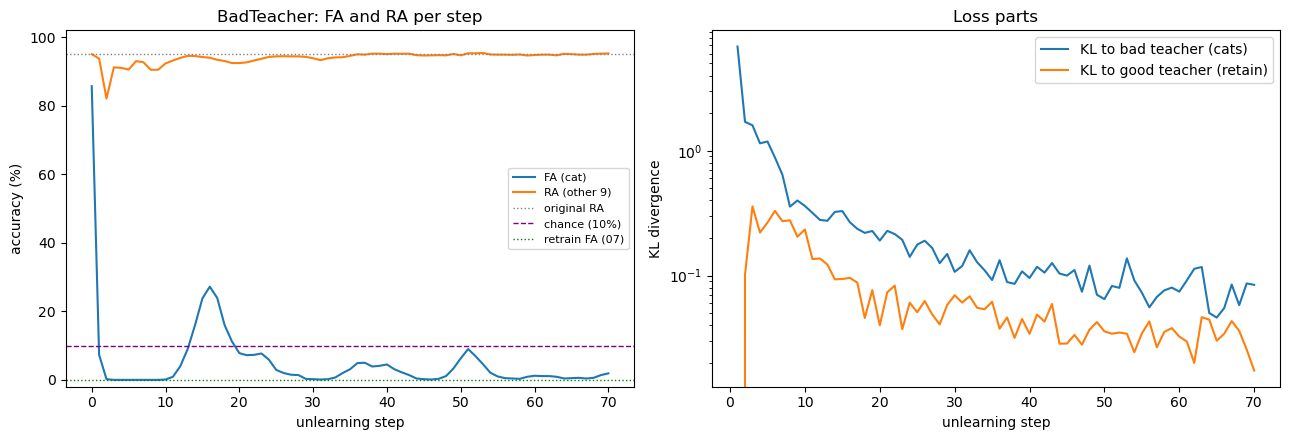

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(hist["step"], np.array(hist["fa"]) * 100, label="FA (cat)")
ax.plot(hist["step"], np.array(hist["ra"]) * 100, label="RA (other 9)")
ax.axhline(ra0 * 100, color="gray", ls=":", lw=1, label="original RA")
ax.axhline(10, color="purple", ls="--", lw=1, label="chance (10%)")
if retrain_ref is not None:
    ax.axhline(retrain_ref["per_class_acc"][FORGET] * 100, color="green", ls=":", lw=1, label="retrain FA (07)")
ax.set(title="BadTeacher: FA and RA per step", xlabel="unlearning step", ylabel="accuracy (%)", ylim=(-2, 102))
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(hist["step"], hist["kl_forget"], label="KL to bad teacher (cats)")
ax.plot(hist["step"], hist["kl_retain"], label="KL to good teacher (retain)")
ax.set(title="Loss parts", xlabel="unlearning step", ylabel="KL divergence", yscale="log")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "09_badteacher_curves.png", dpi=120)
plt.show()

## 7. Compare everything, then free memory

The student is measured on all 10,000 test images, saved to `results/09_badteacher_model.pt` (program 10 attacks it), and then all three models are deleted. The comparison uses numbers only:

- **FA / RA**: the "Done when" check (FA near 10%, RA close to the original).
- **Confidence on cats**: the fingerprint from program 08. Random labels left 29% vs the retrain model's 84%.
- **Where cat images go**: compared with the retrain model (mostly dog) and with the bad teacher itself.

saved the unlearned model to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/09_badteacher_model.pt

               model      FA      RA  cat conf  most common answer for cats
       original (01)   85.7%   94.5%     91.8%  cat (86%)
     BadTeacher (09)    1.9%   94.7%     33.4%  truck (53%)
    GA @ step 7 (08)    0.2%   88.1%     76.8%  dog (57%)
       RL @ end (08)    0.0%   94.4%     29.1%  dog (26%)
        retrain (07)    0.0%   94.9%     83.6%  dog (58%)


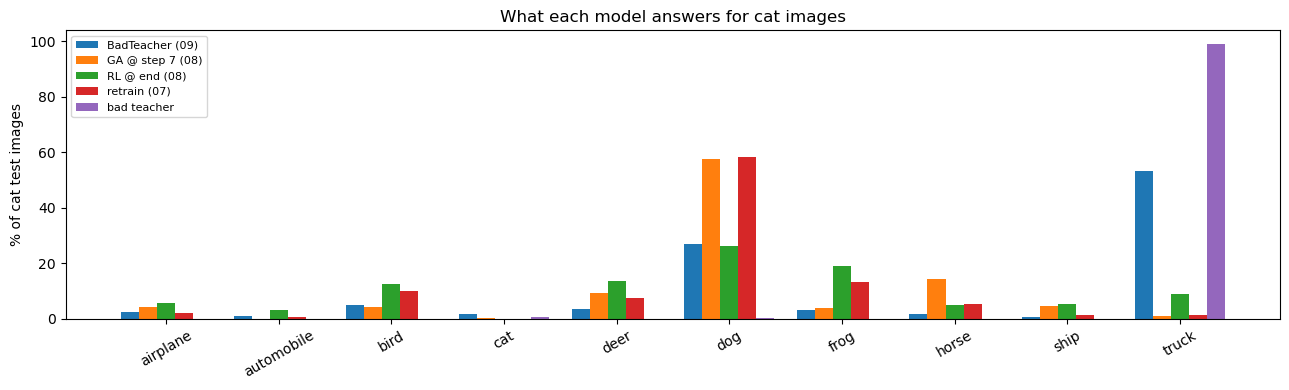

In [7]:
results["BadTeacher (09)"] = full_eval(student)
model_path = RESULTS_DIR / "09_badteacher_model.pt"
torch.save(student.state_dict(), model_path)
print(f"saved the unlearned model to {model_path}\n")

del student, good_teacher, bad_teacher, original, optimizer
free_gpu()

rows = dict(results)
if prog08:
    for name in prog08:
        if name.startswith(("GA @ step", "RL @ end")):
            r = prog08[name]
            rows[name + " (08)"] = {"fa": r["fa"], "ra": r["ra"], "cat_conf": r["cat_conf"], "pred_share": np.array(r["pred_share"])}
if retrain_ref is not None:
    rows["retrain (07)"] = {"fa": float(retrain_ref["per_class_acc"][FORGET]), "ra": ra_retrain,
                            "cat_conf": float(retrain_ref["forget_conf"].mean()), "pred_share": retrain_ref["forget_pred_share"]}

print(f"{'model':>20} {'FA':>7} {'RA':>7} {'cat conf':>9}  most common answer for cats")
for name, r in rows.items():
    top = int(np.argmax(r["pred_share"]))
    print(f"{name:>20} {r['fa']*100:6.1f}% {r['ra']*100:6.1f}% {r['cat_conf']*100:8.1f}%  "
          f"{classes[top]} ({r['pred_share'][top]*100:.0f}%)")

shares = {name: r["pred_share"] for name, r in rows.items() if name != "original (01)"}
shares["bad teacher"] = bad_share
names = list(shares)
x = np.arange(10)
width = 0.8 / len(names)
plt.figure(figsize=(13, 4))
for i, name in enumerate(names):
    plt.bar(x + (i - len(names) / 2 + 0.5) * width, shares[name] * 100, width, label=name)
plt.xticks(x, classes, rotation=30)
plt.ylabel("% of cat test images")
plt.title("What each model answers for cat images")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "09_cat_predictions.png", dpi=120)
plt.show()

## 8. Optional: change the settings

Change a value in section 1 and run again from the top (each run is under 2 minutes). Every run is logged.
- `temperature` 4: softer targets. Does the student copy the bad teacher's *spread* more closely?
- `retain_fraction` 0.1: less retain data. How much does RA suffer?
- `epochs` 3: more unlearning. Does FA keep moving, or does it settle once the student matches the bad teacher? (Gradient ascent never settled.)
- `bad_teacher_seed` 2: a different random bad teacher (seed 1 favours truck, seed 2 frog). Do cats end up in a different class? That shows how much the "forgotten" behaviour depends on an arbitrary random network.

## 9. Log the run

In [8]:
log_run("09_badteacher", SETTINGS,
        {"steps": step, "seconds": round(seconds, 1),
         "bad_teacher_seed": bad_seed,
         "bad_teacher_on_cats": {"pred_share": bad_share.round(4).tolist(), "entropy": round(entropy, 3)},
         "full_test": {name: {k: (np.asarray(v).round(4).tolist() if k == "pred_share" else round(v, 4))
                              for k, v in r.items()} for name, r in results.items()}})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Did FA land near chance (10%), near the retrain model (0%), or somewhere else? Which of the two is the right target, and why do they differ?
2. How close did RA stay to the original, compared with gradient ascent and random labels in program 08?
3. Where does the bad teacher send cat images? Does the student copy that? Is that what a model that never saw cats would do (compare with the retrain model, mostly dog)?
4. Confidence on cats: closer to the retrain model (84%) than random labels (29%)? What would an attacker conclude from each?
5. The student copies a *random* network on cats, and some random networks (seeds 0 and 4) even favour "cat". Is "forgotten" then a well-defined state, or does it depend on luck? How does the retrain model avoid this problem?